In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Data
Chromosome = 358 genes, one per person: 0 = team A, 1 = team B (bit string encoding)

In [2]:
data = np.genfromtxt('HR.csv', delimiter=',', skip_header=1, dtype=str)  # 358 x 5
N = len(data)                                  # 358 people
dept = np.char.strip(data[:, 1])               # remove leading space
dept = np.unique(dept, return_inverse=True)[1] # department id 0..18
H = np.eye(dept.max() + 1)[dept]               # one-hot, 358 x 19
gender = np.unique(data[:, 0], return_inverse=True)[1] # gender id 0..1 (Female, Male)
G = np.eye(gender.max() + 1)[gender]           # one-hot, 358 x 2
S = data[:, 2:].astype(float)                  # weight, height, age: 358 x 3
S = (S - S.mean(axis=0)) / S.std(axis=0)       # same scale for 3 columns

## Fitness (smaller is better)
Balance team A and B by: sport (mean weight / height / age), department, team size, gender

In [3]:
def fitness(pop):
  # pop: 100 x 358, values 0 / 1
  nB = pop.sum(axis=1)                                # 100, people in team B
  nA = N - nB                                         # 100, people in team A
  mB = (pop @ S) / nB[:, None]                        # 100 x 358 @ 358 x 3 = 100 x 3
  mA = (S.sum(axis=0) - pop @ S) / nA[:, None]        # 100 x 3
  sport = np.sum(np.abs(mA - mB), axis=1)             # 100, sport fairness
  dB = pop @ H                                        # 100 x 358 @ 358 x 19 = 100 x 19
  depart = np.sum(np.abs(H.sum(axis=0) - 2 * dB), axis=1) / N  # 100, |A - B| of each dept
  gB = pop @ G                                        # 100 x 358 @ 358 x 2 = 100 x 2
  gender_diff = np.sum(np.abs(G.sum(axis=0) - 2 * gB), axis=1) / N  # 100, |A - B| of each gender
  size = np.abs(nA - nB) / N                          # 100, team size difference
  return sport + depart + size + gender_diff

## Crossover and Mutation

In [4]:
def xover(p1, p2):
  c = np.random.randint(1, len(p1))
  return np.concatenate((p1[:c], p2[c:]))

def mutate(p):
  i = np.random.randint(len(p))
  p[i] = 1 - p[i]                                     # flip one bit
  return p

## GA loop

In [5]:
np.random.seed(0)                                     # same result every run
pop = np.random.randint(0, 2, (100, N))               # 100 x 358
best = []
for g in range(300):
  f = fitness(pop); i = np.argsort(f)
  pop = pop[i]
  best.append(f[i[0]])
  k = 50                                              # selection (keep top 50)
  for i in range(k, len(pop)):                        # reproduction
    p1 = pop[np.random.randint(0, k)]
    p2 = pop[np.random.randint(0, k)]
    pop[i] = xover(p1, p2)
    if np.random.rand() < 0.8:
      pop[i] = mutate(pop[i])
print('fitness =', best[-1])

fitness = 0.0367507284745739


## Visualization

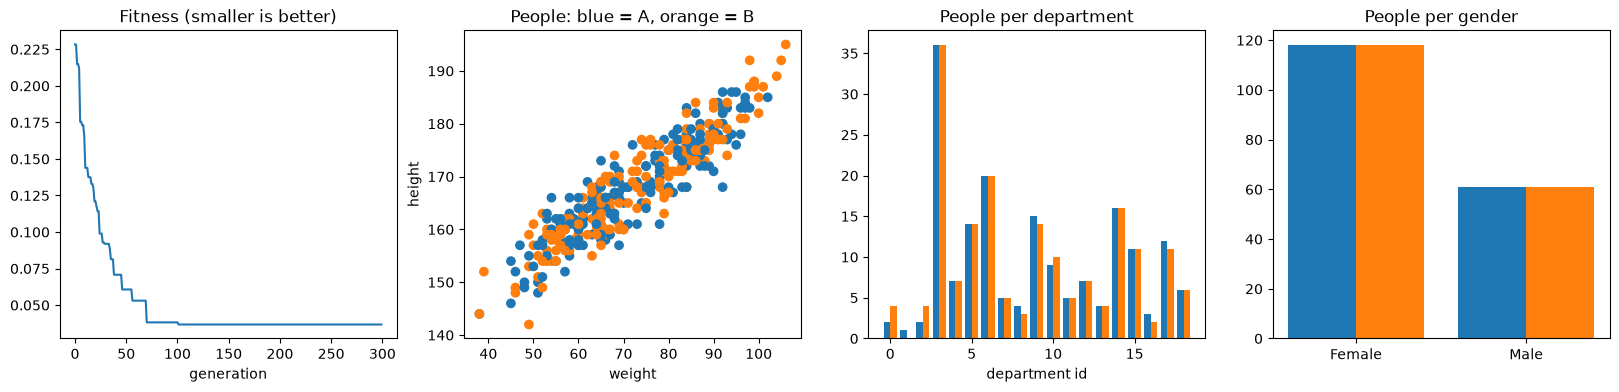

size   A / B : 179 / 179
female A / B : 118 / 118
male   A / B : 61 / 61
weight mean A / B : 72.1 / 72.1
height mean A / B : 167.9 / 167.9
age mean A / B : 41.3 / 41.2


In [6]:
team = pop[0]                                         # best chromosome
color = np.where(team == 0, 'tab:blue', 'tab:orange')
raw = data[:, 2:].astype(float)
fig, ax = plt.subplots(1, 4, figsize=(20, 4))

ax[0].plot(best)                                      # fitness per generation
ax[0].set_title('Fitness (smaller is better)')
ax[0].set_xlabel('generation')

ax[1].scatter(raw[:, 0], raw[:, 1], c=color)          # each person = 1 dot, 2 colors
ax[1].set_title('People: blue = A, orange = B')
ax[1].set_xlabel('weight'); ax[1].set_ylabel('height')

nB = team @ H                                         # 19, team B per department
nA = H.sum(axis=0) - nB                               # 19, team A per department
x = np.arange(len(nA))
ax[2].bar(x - 0.2, nA, 0.4, color='tab:blue')
ax[2].bar(x + 0.2, nB, 0.4, color='tab:orange')
ax[2].set_title('People per department')
ax[2].set_xlabel('department id')
gB = team @ G                                         # 2, team B per gender
gA = G.sum(axis=0) - gB                               # 2, team A per gender
xg = np.arange(len(gA))
ax[3].bar(xg - 0.2, gA, 0.4, color='tab:blue')
ax[3].bar(xg + 0.2, gB, 0.4, color='tab:orange')
ax[3].set_xticks(xg)
ax[3].set_xticklabels(['Female', 'Male'])
ax[3].set_title('People per gender')
plt.show()

print('size   A / B :', int(N - team.sum()), '/', int(team.sum()))
print('female A / B :', int(gA[0]), '/', int(gB[0]))
print('male   A / B :', int(gA[1]), '/', int(gB[1]))
for j, name in enumerate(['weight', 'height', 'age']):
  print(name, 'mean A / B :', raw[team == 0, j].mean().round(1), '/', raw[team == 1, j].mean().round(1))